In [1]:
import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

from glob import glob
import os

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [21]:
paths = glob("*csv")

df = pd.DataFrame()

for path in paths:
    temp = pd.read_csv(path)
    
    df = pd.concat([df, temp], ignore_index=True)
        
df["knowledge"] = "zero-shot"

lora_itens = df["model"].str.contains("Lora"), "knowledge"
df.loc[lora_itens] = "fine-tuning"
df["model"] = df["model"].str.replace("-Lora", "", case=False, regex=False).str.strip()

model_order = [
    "Manaca",
    "Tucano",
    "Cabrita",
    "Sabia",
    "Llama3.1",
    "Qwen3.5",
    "Gemma4",
]

df["model"] = pd.Categorical(
    df["model"],
    categories=model_order,
    ordered=True
)

scenario_order = [
    "original",
    "translation",
    "lexical_swap",
    "grammar_swap",
    "corruption",
    "permutation"
]

df["scenario"] = pd.Categorical(
    df["scenario"],
    categories=scenario_order,
    ordered=True
)


df

,model,scenario,language,original_text_id,text_id,num_words,num_bytes,num_tokens,tokens_per_word,average_nll,total_nll,ppl,bpb,knowledge
0,Sabia,original,portuguese,0,0,74,484,136,1.84,1.99,268.05,7.28,0.80,zero-shot
1,Sabia,original,portuguese,1,1,71,476,199,2.80,2.00,396.13,7.39,1.20,zero-shot
2,Sabia,original,portuguese,2,2,54,425,139,2.57,1.78,246.03,5.95,0.84,zero-shot
3,Sabia,original,portuguese,3,3,68,429,163,2.40,1.74,281.67,5.69,0.95,zero-shot
4,Sabia,original,portuguese,4,4,53,364,115,2.17,1.37,156.10,3.93,0.62,zero-shot
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83995,Sabia,translation,english,995,5995,35,212,46,1.31,5.94,267.20,379.07,1.82,fine-tuning
83996,Sabia,translation,english,996,5996,30,167,40,1.33,3.89,151.87,49.11,1.31,fine-tuning
83997,Sabia,translation,english,997,5997,56,360,92,1.64,4.46,406.17,86.79,1.63,fine-tuning
83998,Sabia,translation,english,998,5998,50,362,85,1.70,4.16,349.37,64.02,1.39,fine-tuning


In [22]:
df["scenario"].unique()

['original', 'permutation', 'corruption', 'grammar_swap', 'lexical_swap', 'translation']
Categories (6, str): ['original' < 'translation' < 'lexical_swap' < 'grammar_swap' < 'corruption' < 'permutation']

In [23]:
df = df[df["model"] != "Gemma4"]


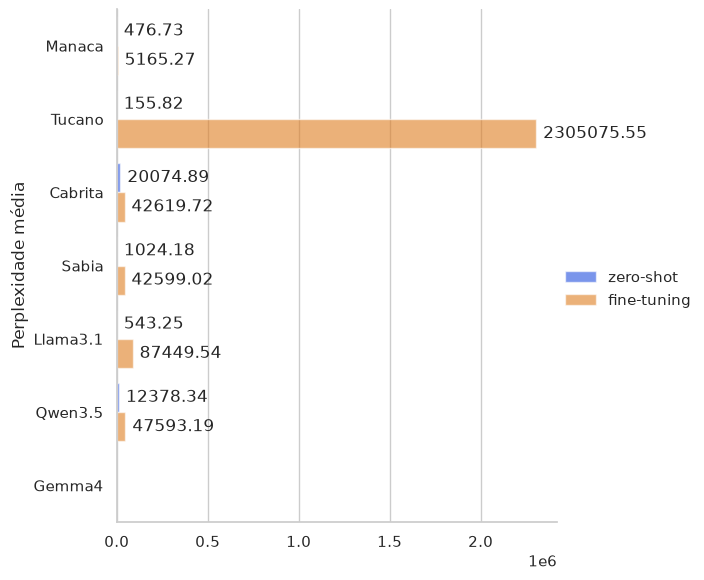

In [24]:
g = sns.catplot(
    data=df,
    kind="bar",
    y="model", x="ppl", orient="h", 
    hue="knowledge",
    estimator="mean", errorbar=None, 
    palette="bright", alpha=.6, height=6, 
)

g.set_axis_labels("", "Perplexidade média")
g.legend.set_title("")

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=5)

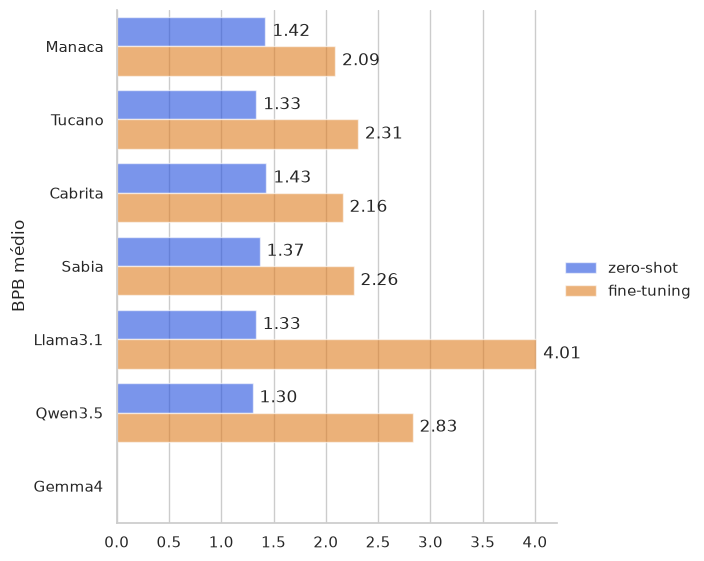

In [14]:
g = sns.catplot(
    data=df,
    kind="bar",
    y="model", x="bpb", orient="h", 
    hue="knowledge",
    estimator="mean", errorbar=None, 
    palette="bright", alpha=.6, height=6, 
)

g.set_axis_labels("", "BPB médio")

g.legend.set_title("")

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=5)

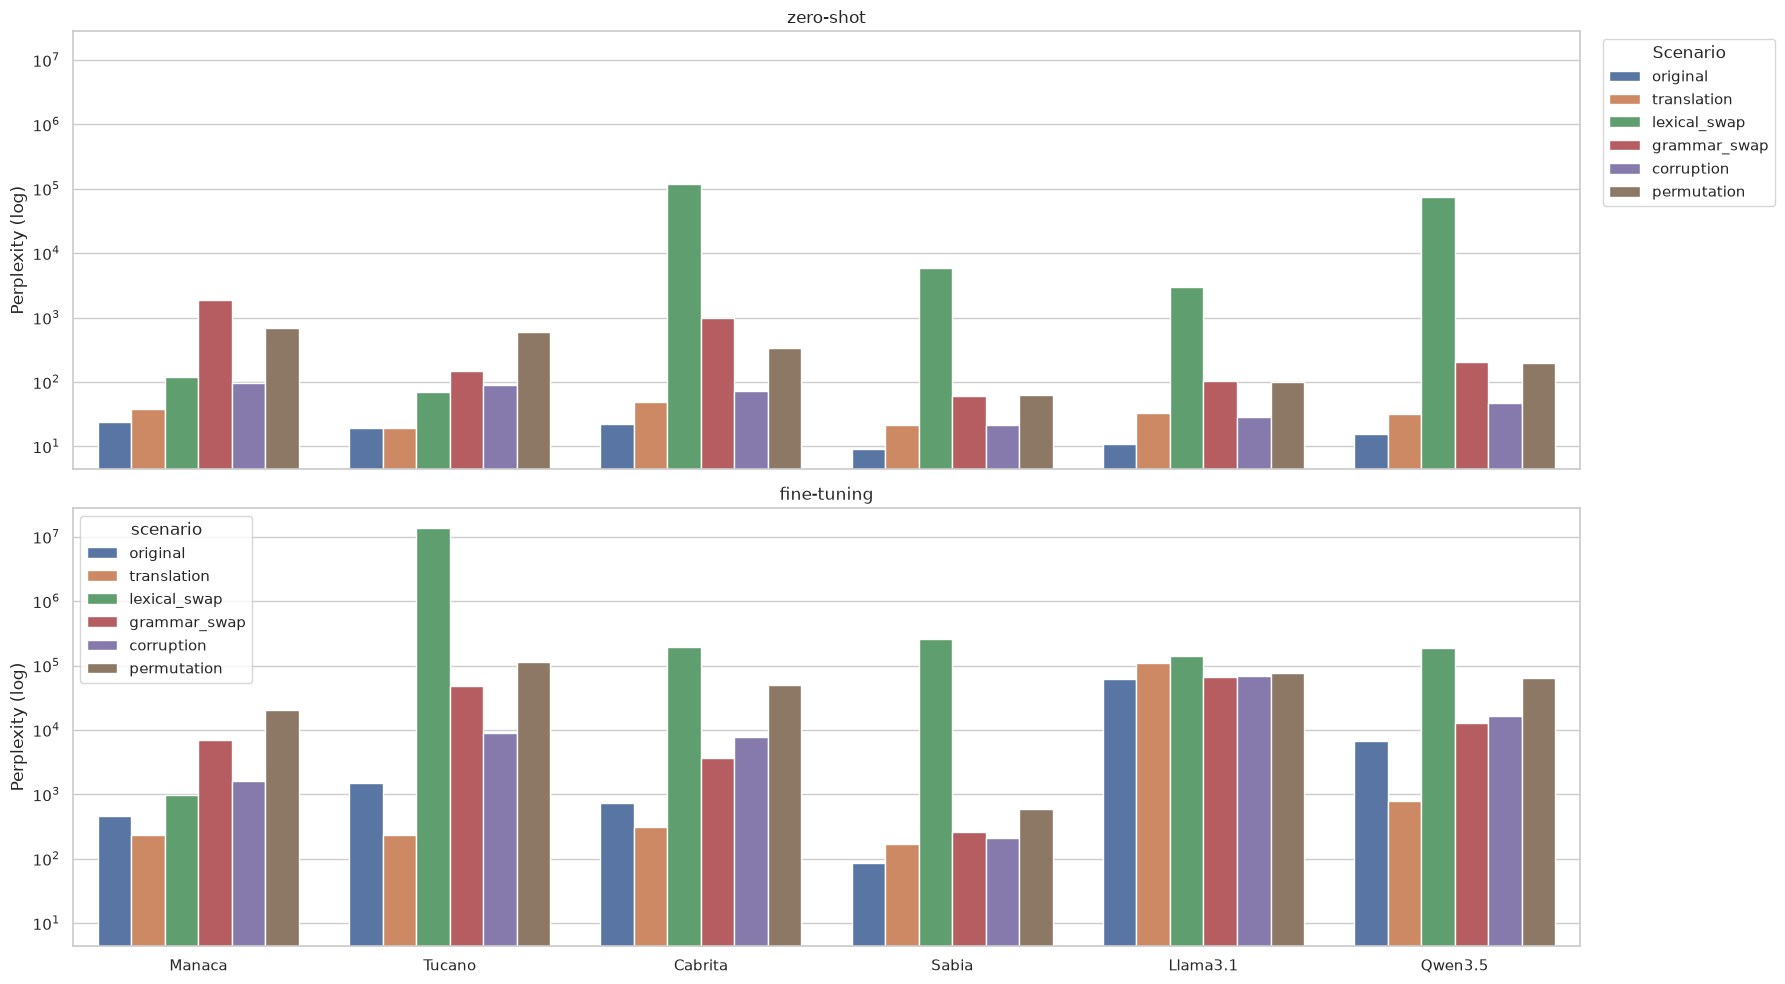

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

metrica = "ppl"

exibir = (
    df
    .groupby(["model", "knowledge", "scenario"], as_index=False)[metrica]
    .mean()
)


model_order = exibir["model"].unique()
scenario_order = exibir["scenario"].unique()

fig, axes = plt.subplots(
    2, 1,
    figsize=(18, 10),
    sharex=True,
    sharey=True
)

for ax, knowledge in zip(axes, ["zero-shot", "fine-tuning"]):
    sns.barplot(
        data=exibir[exibir["knowledge"] == knowledge],
        x="model",
        y=metrica,
        hue="scenario",
        order=model_order,
        hue_order=scenario_order,
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_title(knowledge)
    ax.set_ylabel("Perplexity (log)")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=1)

axes[0].legend(
    title="Scenario",
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)
#axes[1].legend_.remove()

plt.tight_layout()
plt.show()